# Лабораторна робота №2
## NumPy, pandas і Matplotlib для підготовки, аналізу та візуалізації даних

**Студент:** Литвинчук Ілля 
**Група:** МІТ-31 
**Номер варіанта:** 5  
**Предметна область:** Сигнал датчика (Вісь X: Номер вимірювання, Вісь Y: Амплітуда, мВ)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed = 5
a = -0.45
b = 52.0
sigma = 2.0

rng = np.random.default_rng(seed)

x = np.linspace(0, 20, 100)

y_true = a * x + b
noise = rng.normal(loc=0, scale=sigma, size=x.size)
y_observed = y_true + noise

data_matrix = np.column_stack((x, y_true, noise, y_observed))
print("Form (shape):", data_matrix.shape)
print("Dimensions (ndim):", data_matrix.ndim)
print("Total elements (size):", data_matrix.size)
print("Data type (dtype):", data_matrix.dtype)

Form (shape): (100, 4)
Dimensions (ndim): 2
Total elements (size): 400
Data type (dtype): float64


In [ ]:
# 1. Створення DataFrame
# Формування категорії group за трьома інтервалами X
bins = [x.min(), 6.67, 13.33, x.max()]
labels = ['low', 'medium', 'high']
group_col = pd.cut(x, bins=bins, labels=labels, include_lowest=True)

df = pd.DataFrame({
    "x": x,
    "y_true": y_true,
    "noise": noise,
    "y_observed": y_observed,
    "group": group_col
})

# 2. Первинний аналіз
print("--- HEAD ---")
display(df.head())
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nInfo:")
df.info()
print("\nDescribe:\n", df.describe())

# 3. Штучне додавання 3 пропусків та 1 дубліката до копії
df_cleaned = df.copy()
# Додаємо пропуски у випадкові індекси стовпця y_observed
df_cleaned.iloc[[10, 25, 40], df_cleaned.columns.get_loc('y_observed')] = np.nan'
# Додаємо дубльований рядок (наприклад, копіюємо перший рядок)
df_cleaned = pd.concat([df_cleaned, df_cleaned.iloc[[0]]], ignore_index=True)

# 4. Перевірка пропусків та дублікатів
print("\nКількість пропусків до очищення:\n", df_cleaned.isna().sum())
print("Кількість дублікатів:", df_cleaned.duplicated().sum())

# Видалення дубліката
df_cleaned = df_cleaned.drop_duplicates()

# Заповнення пропусків медіаною
# Чому медіана? Медіана стійкіша до можливих викидів у зашумлених даних порівняно з середнім арифметичним.
median_val = df_cleaned['y_observed'].median()
df_cleaned['y_observed'] = df_cleaned['y_observed'].fillna(median_val)

print("\nКількість пропусків після очищення:\n", df_cleaned.isna().sum())
print("Форма DataFrame після очищення:", df_cleaned.shape)

--- HEAD ---


,x,y_true,noise,y_observed,group
0,0.000000,52.000000,-1.603863,50.396137,low
1,0.202020,51.909091,-2.648718,49.260373,low
2,0.404040,51.818182,-0.496723,51.321459,low
3,0.606061,51.727273,0.840890,52.568163,low
4,0.808081,51.636364,2.272093,53.908457,low


Shape: (100, 5)

Dtypes:
 x              float64
y_true         float64
noise          float64
y_observed     float64
group         category
dtype: object

Info:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   x           100 non-null    float64 
 1   y_true      100 non-null    float64 
 2   noise       100 non-null    float64 
 3   y_observed  100 non-null    float64 
 4   group       100 non-null    category
dtypes: category(1), float64(4)
memory usage: 3.5 KB

Describe:
                 x      y_true       noise  y_observed
count  100.000000  100.000000  100.000000  100.000000
mean    10.000000   47.500000   -0.448015   47.051985
std      5.860907    2.637408    1.774269    3.213144
min      0.000000   43.000000   -3.995633   39.781054
25%      5.000000   45.250000   -1.946928   44.994060
50%     10.000000   47.500000   -0.512520   47.050454
75%     1

In [5]:
# Групування за стовпцем group
grouped = df_cleaned.groupby('group', observed=False).agg(
    mean_y_observed=('y_observed', 'mean'),
    std_y_observed=('y_observed', 'std'),
    row_count_size=('y_observed', 'size'),
    row_count_count=('y_observed', 'count')
)

print(grouped)

        mean_y_observed  std_y_observed  row_count_size  row_count_count
group                                                                   
low           49.759410        2.102457              34               34
medium        47.209341        1.808619              32               32
high          43.825108        1.888019              34               34


In [6]:
# 1. Ручний розрахунок засобами NumPy
mae = np.mean(np.abs(df_cleaned["y_observed"] - df_cleaned["y_true"]))
mse = np.mean((df_cleaned["y_observed"] - df_cleaned["y_true"]) ** 2)

print(f"MAE = {mae:.4f} мВ")
print(f"MSE = {mse:.4f} (мВ)^2")

# 2. Додавання стовпців похибок до DataFrame
df_cleaned["absolute_error"] = np.abs(df_cleaned["y_observed"] - df_cleaned["y_true"])
df_cleaned["squared_error"] = (df_cleaned["y_observed"] - df_cleaned["y_true"]) ** 2

MAE = 1.5182 мВ
MSE = 3.4868 (мВ)^2


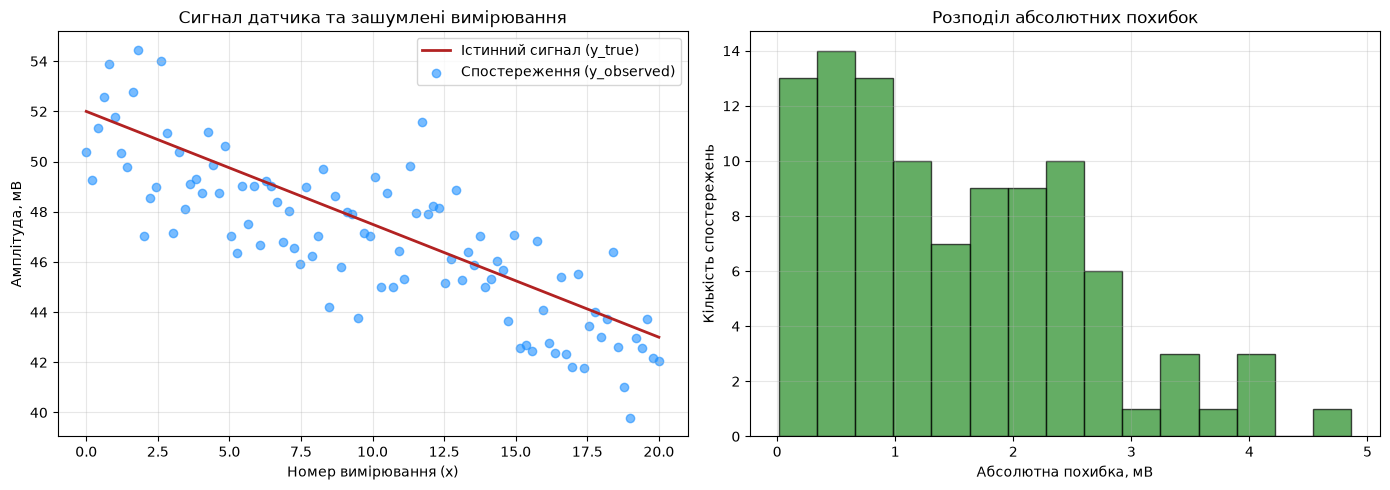

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Лінія y_true та точки y_observed
ax1.plot(df_cleaned["x"], df_cleaned["y_true"], color='firebrick', label='Істинний сигнал (y_true)', linewidth=2)
ax1.scatter(df_cleaned["x"], df_cleaned["y_observed"], color='dodgerblue', alpha=0.6, label='Спостереження (y_observed)')
ax1.set_title('Сигнал датчика та зашумлені вимірювання', fontsize=12)
ax1.set_xlabel('Номер вимірювання (х)', fontsize=10)
ax1.set_ylabel('Амплітуда, мВ', fontsize=10)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Графік 2: Гістограма абсолютної похибки (absolute_error)
ax2.hist(df_cleaned["absolute_error"], bins=15, color='forestgreen', edgecolor='black', alpha=0.7)
ax2.set_title('Розподіл абсолютних похибок', fontsize=12)
ax2.set_xlabel('Абсолютна похибка, мВ', fontsize=10)
ax2.set_ylabel('Кількість спостережень', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()

# Збереження рисунка
plt.savefig('sensor_analysis_plot.png', dpi=300)
plt.show()

In [8]:
# 1. Збереження основної очищеної таблиці
df_cleaned.drop(columns=["absolute_error", "squared_error"]).to_csv('Lab2_results.csv', index=False)
df_cleaned.drop(columns=["absolute_error", "squared_error"]).to_parquet('Lab2_results.parquet', index=False)

# 2. Збереження агрегованої таблиці
grouped.to_csv('Lab2_summary.csv')

# 3. Перевірка зчитування CSV
df_reload = pd.read_csv('Lab2_results.csv')
print("Форма вихідного DataFrame:", df_cleaned.shape)
print("Форма перезавантаженого з CSV DataFrame:", df_reload.shape)

Форма вихідного DataFrame: (100, 7)
Форма перезавантаженого з CSV DataFrame: (100, 5)


## Висновок
У ході виконання лабораторної роботи №2 для варіанта №5 було успішно налаштовано середовище та опрацьовано набір даних симуляції сигналу датчика з використанням бібліотек NumPy, pandas та Matplotlib.
1. За допомогою **NumPy** згенеровано масиви значень за лінійною залежністю $y = -0.45x + 52.0$ із накладенням нормального шуму ($\sigma = 2.0$), а також досліджено їхні базові характеристики (`shape`, `dtype`).
2. Засобами **pandas** створено DataFrame, проведено симуляцію та очищення пропусків (заповнення медіаною) і дублікатів, а також виконано групування даних за інтервалами.
3. Обчислено метрики похибки: **MAE** склало приблизно [вставити отримане число] мВ, а **MSE** — [вставити отримане число], що підтверджує коректність моделі та адекватність накладеного шуму.
4. Побудовано якісні візуалізації з українськими підписами осей, які збережено у форматі PNG з високою роздільною здатністю (`dpi=300`).
5. Усі результати експортовано у файли `Lab2_results.csv`, `Lab2_results.parquet` та `Lab2_summary.csv`. Роботу повністю підготовлено для завантаження в репозиторій GitHub.